# 05. 최종 모델
ExtraTrees + GBM Soft Voting · 35개 피처 (원본 26 + 파생 9, `plate_defect_count` 제외)  
ExtraTrees: SMOTENC 균등화 + class_weight / GBM: 클래스 가중치

In [1]:
import sys, warnings
sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from steel import CLASS_ORDER, CV, RS, SCORING, add_features, cached, final_model, load_data
pd.set_option("display.width", 200); pd.set_option("display.precision", 4)
pd.set_option("display.unicode.east_asian_width", True)   # 한글 출력 정렬
import joblib
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import f1_score, log_loss, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate, RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance

X_train, X_test, y_train, y_test = load_data()
XF, XF_test = add_features(X_train), add_features(X_test)
model = final_model(XF.columns)

## 1. 5-fold CV

In [2]:
# 검증 지표 + Train 점수와의 차이
r = cross_validate(model, XF, y_train, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1)
cv5 = pd.DataFrame({m: [r[f"test_{m}"].mean(), r[f"test_{m}"].std(), r[f"train_{m}"].mean()] for m in SCORING}, index=["val_mean", "val_std", "train_mean"])
cv5

,macro_f1,accuracy,precision,recall
val_mean,0.8319,0.8080,0.8451,0.8257
val_std,0.0161,0.0076,0.0264,0.0179
train_mean,1.0000,1.0000,1.0000,1.0000


## 2. 반복 CV (5×3)

In [3]:
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
rep = cached("final35_repeated", lambda: cross_validate(model, XF, y_train, cv=RCV, scoring="f1_macro", n_jobs=-1)["test_score"])
print(f"repeated CV macro F1 = {rep.mean():.4f} ± {rep.std():.4f}")

repeated CV macro F1 = 0.8368 ± 0.0243


## 3. 학습 곡선

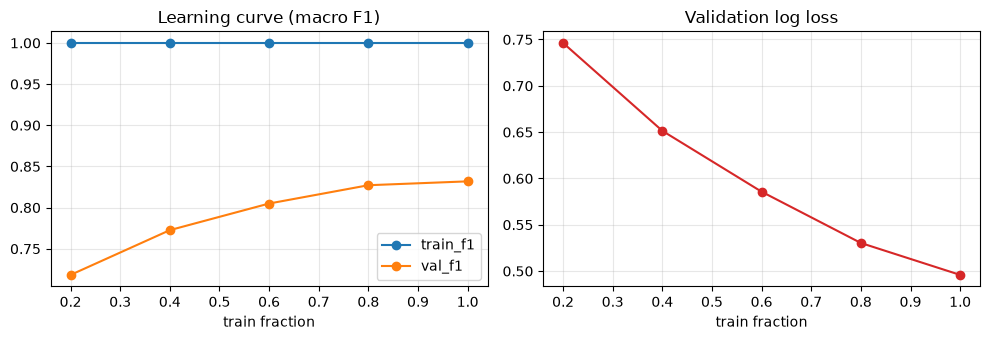

,train_f1,val_f1,val_logloss
frac,,,
0.2,1.0,0.7183,0.7463
0.4,1.0,0.7726,0.6514
0.6,1.0,0.8050,0.5857
0.8,1.0,0.8272,0.5303
1.0,1.0,0.8319,0.4959


In [4]:
# 학습 데이터 20~100%, 5-fold 검증 F1·Log Loss
FRACS = [0.2, 0.4, 0.6, 0.8, 1.0]
def lc_fold(frac, tr, va):
    if frac < 1:   # 학습 fold에서 클래스 비율을 유지하며 일부만 사용
        tr = y_train.iloc[tr].groupby(y_train.iloc[tr], group_keys=False).apply(lambda s: s.sample(frac=frac, random_state=RS)).index
        tr = XF.index.get_indexer(tr)
    m = clone(model).fit(XF.iloc[tr], y_train.iloc[tr])
    p = m.predict_proba(XF.iloc[va])
    return frac, f1_score(y_train.iloc[tr], m.predict(XF.iloc[tr]), average="macro"), \
           f1_score(y_train.iloc[va], m.classes_[p.argmax(1)], average="macro"), log_loss(y_train.iloc[va], p, labels=m.classes_)
lc = cached("final35_learning_curve", lambda: Parallel(n_jobs=-1)(delayed(lc_fold)(f, tr, va) for f in FRACS for tr, va in CV.split(XF, y_train)))
lc = pd.DataFrame(lc, columns=["frac", "train_f1", "val_f1", "val_logloss"]).groupby("frac").mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
lc[["train_f1", "val_f1"]].plot(ax=ax[0], marker="o", title="Learning curve (macro F1)")
lc["val_logloss"].plot(ax=ax[1], marker="o", color="tab:red", title="Validation log loss")
for a in ax: a.set_xlabel("train fraction"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../figures/learning_curve.png", dpi=120); plt.show()
lc
# → 데이터가 늘수록 검증 F1↑, 손실↓, Train-검증 차이↓ → 외운 점수가 아니라 데이터가 늘면 더 좋아질 여지가 있는 상태

## 4. 손실 곡선

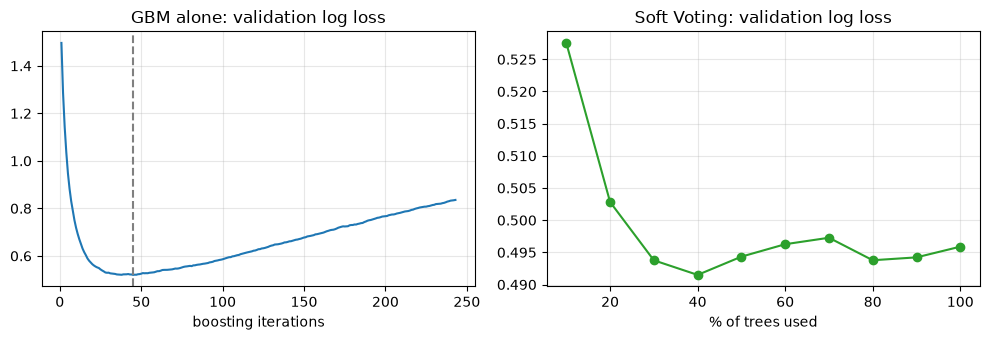

GBM 최소 손실 0.5201 @ 45회 → 마지막 0.8356 | Soft Voting 최소 @ 40%


In [5]:
# 트리 수에 따른 검증 Log Loss (GBM 단독 vs Soft Voting)
def loss_fold(tr, va):
    m = clone(model).fit(XF.iloc[tr], y_train.iloc[tr]); yv = m.le_.transform(y_train.iloc[va])   # VotingClassifier 내부 정수 라벨
    Z = {n: np.asarray(est["prep"].transform(est["plate"].transform(XF.iloc[va]))) for n, est in m.named_estimators_.items()}   # 구성 모델별 전처리 결과 (샘플러는 학습 때만 동작)
    et = m.named_estimators_["extratrees"][-1]
    gbm = m.named_estimators_["gbm"][-1].estimator_
    g_stage = list(gbm.staged_predict_proba(Z["gbm"]))
    gbm_curve = [log_loss(yv, p, labels=gbm.classes_) for p in g_stage]
    tree_mean = lambda f, n: np.mean([t.predict_proba(Z[n]) for t in f.estimators_[:max(1, int(len(f.estimators_) * frac))]], axis=0)
    sv_curve = []
    for frac in np.linspace(0.1, 1, 10):   # 두 모델 모두 트리를 같은 비율만 사용
        pe, pg = tree_mean(et, "extratrees"), g_stage[max(1, int(len(g_stage) * frac)) - 1]
        sv_curve.append(log_loss(yv, (pe + pg) / 2, labels=gbm.classes_))
    return gbm_curve, sv_curve
lcurves = cached("final35_loss_curve", lambda: Parallel(n_jobs=-1)(delayed(loss_fold)(tr, va) for tr, va in CV.split(XF, y_train)))
gbm_loss, sv_loss = np.mean([c[0] for c in lcurves], axis=0), np.mean([c[1] for c in lcurves], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, len(gbm_loss) + 1), gbm_loss); ax[0].axvline(gbm_loss.argmin() + 1, ls="--", c="gray")
ax[0].set(title="GBM alone: validation log loss", xlabel="boosting iterations")
ax[1].plot(np.linspace(10, 100, 10), sv_loss, marker="o", c="tab:green"); ax[1].set(title="Soft Voting: validation log loss", xlabel="% of trees used")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../figures/loss_curve.png", dpi=120); plt.show()
print(f"GBM 최소 손실 {gbm_loss.min():.4f} @ {gbm_loss.argmin() + 1}회 → 마지막 {gbm_loss[-1]:.4f} | Soft Voting 최소 @ {np.linspace(10, 100, 10)[sv_loss.argmin()]:.0f}%")
# → GBM 단독은 후반에 확률 과신으로 손실이 다시 오르지만, Soft Voting은 다시 오르지 않고 평탄하게 유지 (ExtraTrees의 완만한 확률이 GBM의 과신을 상쇄)

## 5. Test 평가

In [6]:
# 모델·설정 확정 후 1회
model.fit(XF, y_train)
pred, proba = model.predict(XF_test), model.predict_proba(XF_test)
rng = np.random.default_rng(RS)
boot = [f1_score(y_test.values[i], pred[i], average="macro") for i in (rng.integers(0, len(y_test), len(y_test)) for _ in range(2000))]
print(f"Test macro F1 = {f1_score(y_test, pred, average='macro'):.4f}  (95% CI {np.percentile(boot, 2.5):.4f} ~ {np.percentile(boot, 97.5):.4f})")
print(f"Accuracy = {accuracy_score(y_test, pred):.4f}")
print(classification_report(y_test, pred, labels=CLASS_ORDER, digits=4))

Test macro F1 = 0.8109  (95% CI 0.7663 ~ 0.8487)
Accuracy = 0.7789
              precision    recall  f1-score   support

Other_Faults     0.7153    0.7259    0.7206       135
       Bumps     0.7125    0.7037    0.7081        81
   K_Scratch     0.9600    0.9231    0.9412        78
   Z_Scratch     0.9722    0.9211    0.9459        38
      Pastry     0.5135    0.5938    0.5507        32
      Stains     0.8571    0.8571    0.8571        14
   Dirtiness     1.0000    0.9091    0.9524        11

    accuracy                         0.7789       389
   macro avg     0.8187    0.8048    0.8109       389
weighted avg     0.7854    0.7789    0.7817       389



## 6. Confusion Matrix

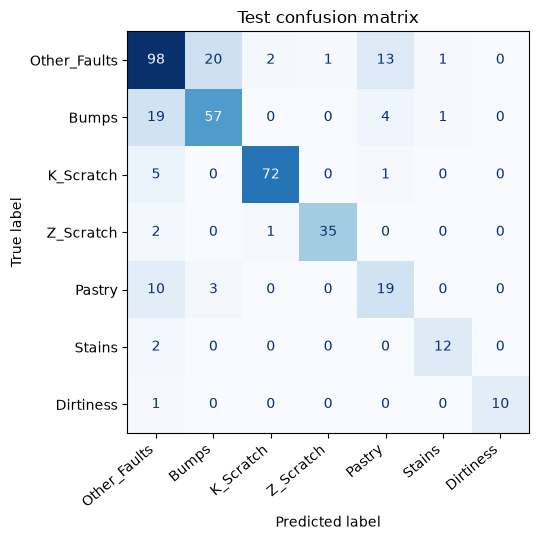

오분류 86건 | Bumps↔Other_Faults 39건 | Pastry↔Other_Faults 23건


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=CLASS_ORDER), display_labels=CLASS_ORDER).plot(ax=ax, cmap="Blues", colorbar=False)
plt.xticks(rotation=40, ha="right"); plt.title("Test confusion matrix"); plt.tight_layout()
plt.savefig("../figures/confusion_matrix.png", dpi=120); plt.show()
err = pd.Series(pred != y_test.values, index=y_test.index)
pair = lambda a, b: ((y_test == a) & (pred == b)).sum() + ((y_test == b) & (pred == a)).sum()
print(f"오분류 {err.sum()}건 | Bumps↔Other_Faults {pair('Bumps', 'Other_Faults')}건 | Pastry↔Other_Faults {pair('Pastry', 'Other_Faults')}건")
# → 오류 대부분이 서로 닮은 Bumps·Pastry·Other_Faults 경계에 집중

## 7. 변수 중요도 (Permutation)

In [8]:
# 상위 10개, Test Macro F1 감소량
pi = permutation_importance(model, XF_test, y_test, scoring="f1_macro", n_repeats=5, random_state=RS, n_jobs=-1)
pd.Series(pi.importances_mean, index=XF_test.columns).sort_values(ascending=False).head(10).to_frame("F1 drop")
# → 생산 조건(두께·폭·강종) 의존도 확인. plate_defect_count를 빼도 강종·두께처럼 새 조건에도 통하는 정보는 그대로 사용

,F1 drop
Steel_Plate_Thickness,0.1010
Length_of_Conveyer,0.0896
x_center_rel,0.0237
TypeOfSteel_A300,0.0187
Orientation_Index,0.0098
x_straightness,0.0066
X_Perimeter,0.0052
Edges_Y_Index,0.0039
Empty_Index,0.0036
SigmoidOfAreas,0.0030


## 8. 모델 저장

In [9]:
joblib.dump(model, "../models/final_model.pkl", compress=3)   # 입력: add_features(X) 적용 데이터

['../models/final_model.pkl']